## Time series forecasting prediction for NIFTY-50 dataset

*   List item
*   List item



##### 1. Import Necessary Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, SimpleRNN
from keras.optimizers import Adam


#### 2. Load the Data

We’ll load the stock data for “RELIANCE” from the NIFTY-50 dataset and set the date as the index.

The historic Closing Price is the target variable to predict.

VWAP (Volume Weighted Average Price) is a trading benchmark used by traders that gives the average price the stock has traded at throughout the day, based on both volume and price.

- We use pd.read_csv to load the CSV file containing the stock data.
- The Date column is converted to datetime format using pd.to_datetime.
- We set the Date column as the index of the DataFrame for easier time series manipulation.

In [ ]:
# Load the data
import os
# Get the current working directory
current_path = os.getcwd()

data = pd.read_csv(current_path+r'\NIFTY50_stock_data\RELIANCE.csv')
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
print(data.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content\\NIFTY50_stock_data\\RELIANCE.csv'

##### 3. Exploratory Data Analysis (EDA)
- data.describe() provides summary statistics of the dataset, including count, mean, standard deviation, min, and max values.
- data.isnull().sum() checks for missing values in each column.

In [ ]:
# Basic statistics
print(data.describe())

# Check for missing values
print(data.isnull().sum())

        Prev Close         Open         High          Low         Last  \
count  5306.000000  5306.000000  5306.000000  5306.000000  5306.000000   
mean   1010.984866  1012.602375  1026.823803   996.886977  1011.157143   
std     570.987079   572.575893   581.986757   560.703328   570.938608   
min     203.200000   205.500000   219.500000   197.150000   203.300000   
25%     572.137500   572.925000   582.950000   564.237500   572.062500   
50%     937.950000   939.000000   950.075000   927.550000   939.025000   
75%    1247.387500  1247.675000  1267.350000  1227.450000  1248.287500   
max    3220.850000  3298.000000  3298.000000  3141.300000  3223.000000   

             Close         VWAP        Volume      Turnover        Trades  \
count  5306.000000  5306.000000  5.306000e+03  5.306000e+03  2.456000e+03   
mean   1011.316839  1011.937409  5.583028e+06  6.076715e+14  1.452306e+05   
std     571.046753   571.222520  4.983793e+06  8.369739e+14  1.297557e+05   
min     203.200000   212.

##### 4. Plot the Closing Price
Visualize the closing price over time to get an initial sense of the data.

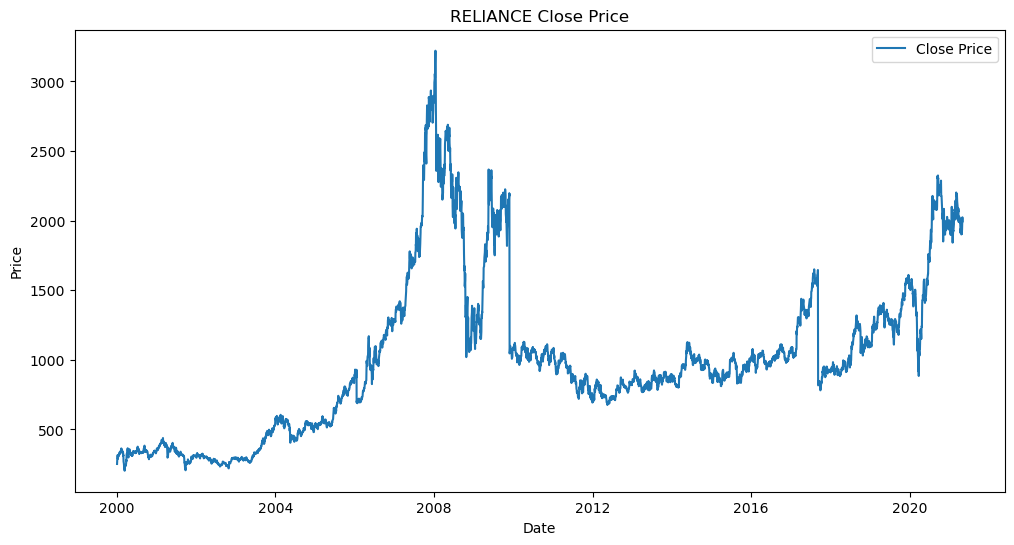

In [ ]:
# Plot the closing price
plt.figure(figsize=(12, 6))
plt.plot(data['Close'], label='Close Price')
plt.title('RELIANCE Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()


##### 5. Check for Data Issues
- We check for missing values again to ensure data integrity.
- If there are any missing values, we use forward fill (ffill) to fill them, which propagates the last valid observation forward.

In [ ]:
# Plot the closing price
plt.figure(figsize=(12, 6))
plt.plot(data['Close'], label='Close Price')
plt.title('RELIANCE Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()


Symbol                   0
Series                   0
Prev Close               0
Open                     0
High                     0
Low                      0
Last                     0
Close                    0
VWAP                     0
Volume                   0
Turnover                 0
Trades                2850
Deliverable Volume     514
%Deliverble            514
dtype: int64


C:\Users\ashar\AppData\Local\Temp\ipykernel_5208\187001741.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data.fillna(method='ffill', inplace=True)


##### 7. Prepare the Data for RNN
Scale the data and create sequences for the RNN model.
- We use MinMaxScaler to scale the closing prices to a range between 0 and 1, which helps the RNN model converge faster.
- The create_sequences function generates sequences of a specified length (seq_length) from the scaled data. Each sequence is used as input to the RNN, and the corresponding next value is the target.
- We split the data into training and testing sets, with 80% of the data used for training and 20% for testing.

In [ ]:
# Prepare the data for RNN
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data[['Close']])

# Create sequences
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 60
X, y = create_sequences(data_scaled, seq_length)

# Split the data into training and testing sets
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


##### Build the RNN Model
The model consists of a single RNN layer with 50 units and ReLU activation, followed by a dense layer with one unit to predict the closing price.

In [ ]:
# Build the RNN model
model = Sequential()
model.add(SimpleRNN(50, activation='relu', input_shape=(seq_length, 1)))
model.add(Dense(1))
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')


#### 9. Train the Model

In [ ]:
# Train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50
132/132 [==============================] - 2s 10ms/step - loss: 0.0031 - val_loss: 3.8086e-04
Epoch 2/50
132/132 [==============================] - 1s 10ms/step - loss: 2.7811e-04 - val_loss: 3.8818e-04
Epoch 3/50
132/132 [==============================] - 1s 9ms/step - loss: 2.6983e-04 - val_loss: 3.6043e-04
Epoch 4/50
132/132 [==============================] - 1s 9ms/step - loss: 2.5482e-04 - val_loss: 3.1836e-04
Epoch 5/50
132/132 [==============================] - 1s 9ms/step - loss: 2.5328e-04 - val_loss: 2.8042e-04
Epoch 6/50
132/132 [==============================] - 1s 9ms/step - loss: 2.2137e-04 - val_loss: 2.8398e-04
Epoch 7/50
132/132 [==============================] - 1s 9ms/step - loss: 2.2001e-04 - val_loss: 3.0898e-04
Epoch 8/50
132/132 [==============================] - 1s 9ms/step - loss: 1.9488e-04 - val_loss: 2.2592e-04
Epoch 9/50
132/132 [==============================] - 1s 9ms/step - loss: 1.8016e-04 - val_loss: 2.1284e-04
Epoch 10/50
132/132 [=========

#### 10. Make Predictions
- We use the trained model to make predictions on the test data.
- The predicted values are scaled back to the original range using the inverse transform of the scaler.

In [ ]:
# Make predictions
predicted = model.predict(X_test)
predicted = scaler.inverse_transform(predicted)
y_test = scaler.inverse_transform(y_test)

33/33 [==============================] - 1s 8ms/step


#### 11. Plot Actual vs Predicted
Visualize the actual and predicted closing prices.

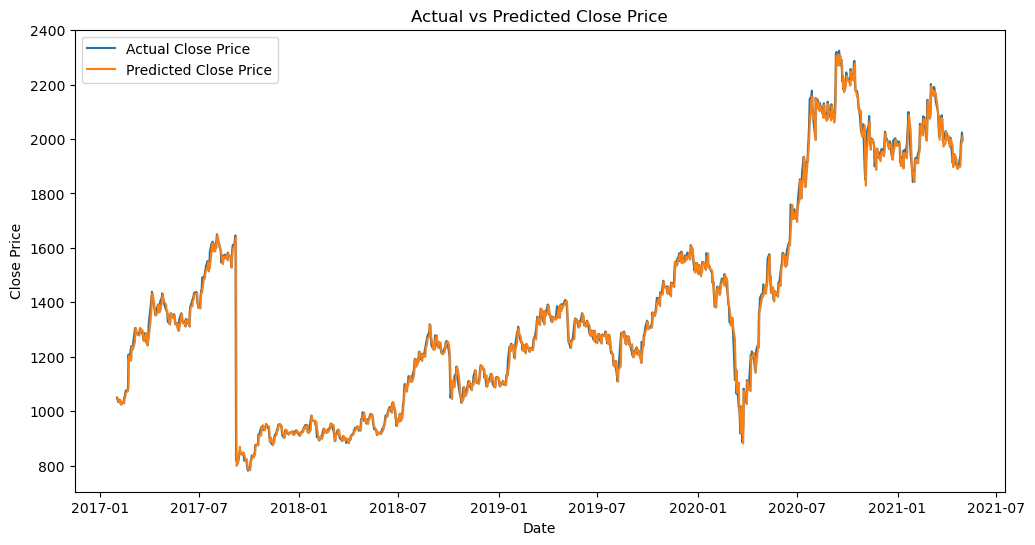

In [ ]:
# Plot actual vs predicted
plt.figure(figsize=(12, 6))
plt.plot(data.index[seq_length+split:], y_test, label='Actual Close Price')
plt.plot(data.index[seq_length+split:], predicted, label='Predicted Close Price')
plt.title('Actual vs Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()
